Ishika Reddy 
Module 2 Assignment 
October 23, 2026

In [15]:
import pandas as pd

#IMDb's official daily-updated datasets
basics = pd.read_csv("https://datasets.imdbws.com/title.basics.tsv.gz",
                     sep="\t", na_values="\\N", low_memory=False,
                     usecols=["tconst", "titleType", "primaryTitle", "startYear", "runtimeMinutes", "genres"])
ratings = pd.read_csv("https://datasets.imdbws.com/title.ratings.tsv.gz",
                      sep="\t", na_values="\\N")

#Feature films from 2000 onward
movies = basics[(basics["titleType"] == "movie") & (basics["startYear"] >= 2000)]
movies = movies.merge(ratings, on="tconst")

print(movies.shape)
movies.head()

(215979, 8)


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres,averageRating,numVotes
0,tt0035423,movie,Kate & Leopold,2001.0,118,"Comedy,Fantasy,Romance",6.4,95075
1,tt0062336,movie,The Tango of the Widower and Its Distorting Mi...,2020.0,70,"Drama,Mystery",6.3,299
2,tt0065414,movie,Appunti per un romanzo sull'immondezza,2022.0,85,Documentary,6.9,41
3,tt0069049,movie,The Other Side of the Wind,2018.0,122,Drama,6.6,8651
4,tt0070596,movie,Socialist Realism,2023.0,78,"Drama,History",6.8,245


In [17]:
import numpy as np

# Make sure runtime is a number
# Drop movies missing any key info
movies["runtimeMinutes"] = pd.to_numeric(movies["runtimeMinutes"], errors="coerce")
movies = movies.dropna(subset=["genres", "averageRating", "numVotes", "runtimeMinutes"])

# Keep movies with at least 1,000 votes (so ratings are meaningful)
# released 2000-2024 (very new movies haven't had time to collect votes)
# and a normal feature-film runtime (60-240 minutes)
movies = movies[(movies["numVotes"] >= 1000) &
                (movies["startYear"] <= 2024) &
                (movies["runtimeMinutes"].between(60, 240))]

print(movies.shape)
movies[["averageRating", "numVotes", "runtimeMinutes"]].describe()

(30745, 8)


,averageRating,numVotes,runtimeMinutes
count,30745.000000,3.074500e+04,30745.000000
mean,6.097157,2.868506e+04,106.518231
std,1.192905,1.031718e+05,20.875299
min,1.000000,1.000000e+03,60.000000
25%,5.400000,1.700000e+03,92.000000
50%,6.300000,3.426000e+03,101.000000
75%,7.000000,1.151900e+04,117.000000
max,9.800000,3.245271e+06,238.000000


In [19]:
from sklearn.preprocessing import StandardScaler

# Votes range from 1,000 to 2,000,000+, so use a log scale
movies["log_votes"] = np.log10(movies["numVotes"])

# Standardize rating, popularity, and runtime so they're on the same scale
numeric = StandardScaler().fit_transform(movies[["averageRating", "log_votes", "runtimeMinutes"]])
numeric_df = pd.DataFrame(numeric, columns=["rating_z", "votes_z", "runtime_z"], index=movies.index)

# Turn the genre list into 0/1 columns (Comedy, Drama, Horror, ...)
genre_df = movies["genres"].str.get_dummies(sep=",")

# Down-weight genres so clusters are driven mainly by rating and popularity
GENRE_WEIGHT = 0.5
features = pd.concat([numeric_df, genre_df * GENRE_WEIGHT], axis=1)
print(features.shape)

#CLAUDE ASSISTANCE

(30745, 25)


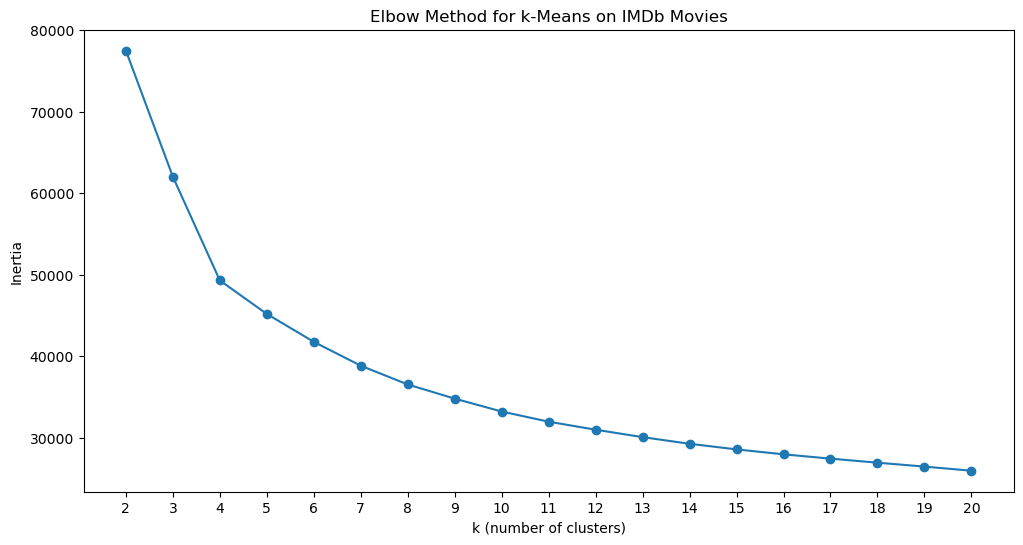

In [21]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_scores = []
for test_k in range(2, 21):
    tmp_model = KMeans(n_clusters=test_k, n_init=10, random_state=42)
    tmp_model.fit(features)
    inertia_scores.append((test_k, tmp_model.inertia_))

inertia_df = pd.DataFrame(inertia_scores, columns=["k", "inertia"])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(inertia_df["k"], inertia_df["inertia"], marker="o")
ax.set_xlabel("k (number of clusters)")
ax.set_ylabel("Inertia")
ax.set_title("Elbow Method for k-Means on IMDb Movies")
ax.set_xticks(range(2, 21))
plt.show()
#DEBUGGED W CLAUDE 

In [23]:
k = 4

model = KMeans(n_clusters=k, n_init=10, random_state=42)
movies["cluster"] = model.fit_predict(features)

# Summary table: size, average rating, median votes, runtime, top genres
summary = movies.groupby("cluster").agg(
    size=("tconst", "count"),
    avg_rating=("averageRating", "mean"),
    median_votes=("numVotes", "median"),
    avg_runtime=("runtimeMinutes", "mean")
).round(2)

summary["top_genres"] = genre_df.groupby(movies["cluster"]).mean().apply(
    lambda row: ", ".join(row.sort_values(ascending=False).head(3).index), axis=1)

summary.sort_values("avg_rating", ascending=False)

,size,avg_rating,median_votes,avg_runtime,top_genres
cluster,,,,,
3,4954,6.69,3335.5,141.44,"Drama, Action, Comedy"
0,5757,6.61,58374.0,108.67,"Drama, Comedy, Action"
1,12535,6.57,2460.0,98.94,"Drama, Comedy, Romance"
2,7499,4.52,2291.0,94.46,"Horror, Drama, Comedy"


In [25]:
for c, group in movies.groupby("cluster"):
    print(f"\nCluster {c} ({len(group)} movies)")
    print("  Most-voted:")
    for _, row in group.nlargest(3, "numVotes").iterrows():
        print(f"    {row['primaryTitle']} ({int(row['startYear'])}) - {row['averageRating']}/10, {int(row['numVotes']):,} votes, {row['genres']}")
    print("  Random sample:")
    for _, row in group.sample(3, random_state=42).iterrows():
        print(f"    {row['primaryTitle']} ({int(row['startYear'])}) - {row['averageRating']}/10, {int(row['numVotes']):,} votes, {row['genres']}")

#CLAUDE ASSISTANCE TO VERIFY & VISUALIZE


Cluster 0 (5757 movies)
  Most-voted:
    The Dark Knight (2008) - 9.1/10, 3,245,271 votes, Crime,Thriller
    Inception (2010) - 8.8/10, 2,884,847 votes, Adventure,Sci-Fi,Thriller
    Interstellar (2014) - 8.7/10, 2,627,617 votes, Adventure,Sci-Fi
  Random sample:
    The Machine (2023) - 5.7/10, 18,398 votes, Action,Comedy
    That's My Boy (2012) - 5.6/10, 124,163 votes, Comedy,Drama
    The Collini Case (2019) - 7.3/10, 15,889 votes, Crime,Drama,Thriller

Cluster 1 (12535 movies)
  Most-voted:
    The Party (2017) - 6.6/10, 23,184 votes, Comedy,Drama
    Petite Maman (2021) - 7.3/10, 21,422 votes, Drama,Fantasy
    Yes, God, Yes (2019) - 6.1/10, 20,781 votes, Comedy,Drama
  Random sample:
    Main Aur Charles (2015) - 6.2/10, 1,909 votes, Action,Biography,Crime
    Phoebe in Wonderland (2008) - 7.0/10, 8,312 votes, Drama
    The Spine of Night (2021) - 6.5/10, 3,697 votes, Action,Adventure,Animation

Cluster 2 (7499 movies)
  Most-voted:
    Radhe (2021) - 1.8/10, 182,156 votes, A

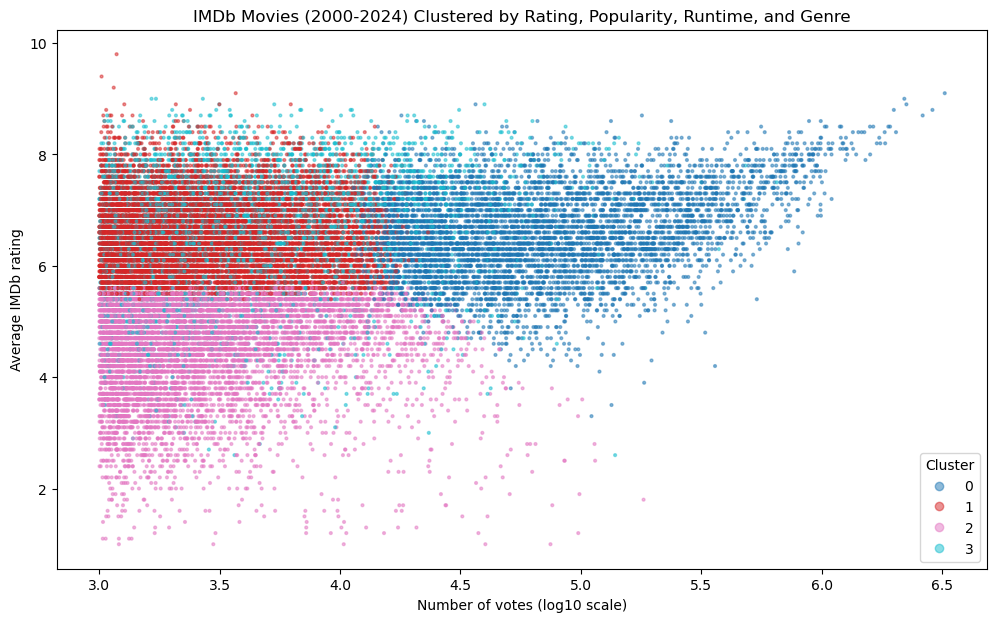

In [27]:
fig, ax = plt.subplots(figsize=(12, 7))
scatter = ax.scatter(movies["log_votes"], movies["averageRating"],
                     c=movies["cluster"], cmap="tab10", s=4, alpha=0.5)
ax.set_xlabel("Number of votes (log10 scale)")
ax.set_ylabel("Average IMDb rating")
ax.set_title("IMDb Movies (2000-2024) Clustered by Rating, Popularity, Runtime, and Genre")
ax.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [41]:
#Movies I've watched and consider underrated
my_picks = ["Emoji Movie"] 

for title in my_picks:
    match = movies[movies["primaryTitle"].str.lower() == title.lower()]
    if len(match) == 0:
        print(f"{title}: not found (check spelling, or it may have fewer than 1,000 votes)")
    else:
        print(match[["primaryTitle", "startYear", "averageRating", "numVotes", "cluster"]].to_string(header=False))

Emoji Movie: not found (check spelling, or it may have fewer than 1,000 votes)


In [31]:
#Check if years are gonna be 
print(movies["startYear"].min(), movies["startYear"].max())

2000.0 2024.0


In [33]:
# VALIDATION CHECKS

# 1. Input data: year range and missing values
print("Year range:", int(movies["startYear"].min()), "-", int(movies["startYear"].max()))
print("Total movies after filtering:", len(movies))
print("\nMissing values per column:")
print(movies[["averageRating", "numVotes", "runtimeMinutes", "genres"]].isna().sum())

# 2. Input data: make sure values are in a sensible range
print("\nRating range:", movies["averageRating"].min(), "-", movies["averageRating"].max())
print("Votes range:", int(movies["numVotes"].min()), "-", int(movies["numVotes"].max()))
print("Runtime range:", int(movies["runtimeMinutes"].min()), "-", int(movies["runtimeMinutes"].max()))

# 3. Output: movies I've watched and consider underrated
print("\nMy picks:")
my_picks = ["Fat Girl", "The Piano Teacher", "Terrifier 3"]

for title in my_picks:
    match = movies[movies["primaryTitle"].str.lower() == title.lower()]
    if len(match) == 0:
        print(f"{title}: not found (check spelling, or it may have fewer than 1,000 votes)")
    else:
        print(match[["primaryTitle", "startYear", "averageRating", "numVotes", "cluster"]].to_string(index=False, header=False))

Year range: 2000 - 2024
Total movies after filtering: 30745

Missing values per column:
averageRating     0
numVotes          0
runtimeMinutes    0
genres            0
dtype: int64

Rating range: 1.0 - 9.8
Votes range: 1000 - 3245271
Runtime range: 60 - 238

My picks:
Fat Girl 2001.0 6.4 14319 1
The Piano Teacher 2001.0 7.5 83547 0
Terrifier 3 2024.0 6.2 66305 0


In [35]:
print("\nFamous movies:")
check_ids = ["tt1375666", "tt6751668", "tt0368226"]
print(movies[movies["tconst"].isin(check_ids)][["primaryTitle", "startYear", "averageRating", "numVotes", "cluster"]].to_string(index=False))


Famous movies:
primaryTitle  startYear  averageRating  numVotes  cluster
    The Room     2003.0            3.6    101305        2
   Inception     2010.0            8.8   2884847        0
    Parasite     2019.0            8.5   1206081        0


In [39]:
movies.to_csv("imdb_movies_snapshot.csv", index=False)

In [49]:
my_indian_movies = ["Baahubali", "Ye Maaya Chesave", "Dear Comrade"]  # <-- movies you've seen

for title in my_indian_movies:
    match = movies[movies["primaryTitle"].str.lower().str.contains(title.lower(), regex=False)]
    if len(match) == 0:
        print(f"{title}: not found")
    else:
        print(match[["primaryTitle", "startYear", "averageRating", "numVotes", "runtimeMinutes", "cluster"]].to_string(index=False, header=False))

     Sri Bharatha Baahubali 2020.0 4.0   1177 164.0 3
   Baahubali: The Beginning 2015.0 8.0 157544 159.0 0
Baahubali 2: The Conclusion 2017.0 8.2 137519 167.0 3
Ye Maaya Chesave 2010.0 7.7 3754 155.0 3
Dear Comrades! 2020.0 7.3  6598 121.0 3
  Dear Comrade 2019.0 7.3 11949 169.0 3
